In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.data.load_master_data import load_master_data

df = load_master_data()

df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 46 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   season                             25939 non-null  int64         
 1   round                              25939 non-null  int64         
 2   driver_id                          25939 non-null  category      
 3   driver_name                        25939 non-null  category      
 4   constructor_id                     25939 non-null  category      
 5   grid                               25939 non-null  int64         
 6   position                           25939 non-null  int64         
 7   points                             25939 non-null  float64       
 8   laps                               25939 non-null  int64         
 9   status                             25939 non-null  category      
 10  time                               8354 non-n

In [3]:
target = "podium"

df[target].value_counts()

df[target].value_counts(normalize=True)

podium
0    0.865916
1    0.134084
Name: proportion, dtype: float64

In [4]:
features = [
    "grid",
    "qualifying_position",
    "driver_age",
    "pole_position",
    "front_row",
    "constructor_name",
    "driver_nationality",
    "circuit_country",
    "current_season_points",
    "avg_points_per_season",
    "constructor_points_current_season",
    "points_last_5_races"
]

descriminative_numerical_features = ["q1_seconds", "q2_seconds", "q3_seconds", "weighted_points_at_circuit", "driver_circuit_delta"]
descriminative_categorical_features = ["circuit_id"]

In [5]:
X = df[features]

y = df[target]

In [6]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   grid                               25939 non-null  int64   
 1   qualifying_position                25939 non-null  int64   
 2   driver_age                         25939 non-null  float64 
 3   pole_position                      25939 non-null  int64   
 4   front_row                          25939 non-null  int64   
 5   constructor_name                   25939 non-null  category
 6   driver_nationality                 25939 non-null  str     
 7   circuit_country                    25939 non-null  category
 8   current_season_points              25939 non-null  float64 
 9   avg_points_per_season              25939 non-null  float64 
 10  constructor_points_current_season  25939 non-null  float64 
 11  points_last_5_races                25939 non-null  f

## GRID T TEST

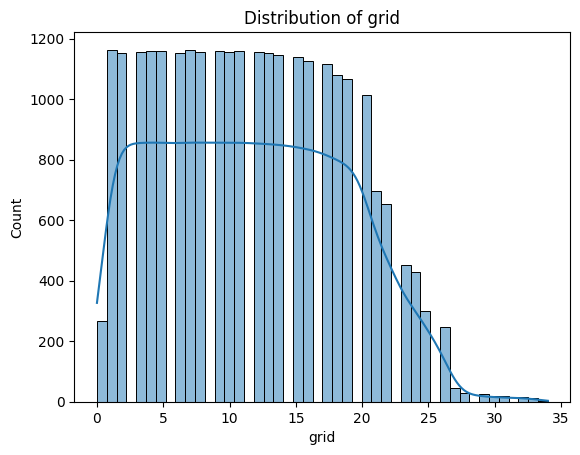

In [7]:
from src.visualization.hist import hist

hist(df, "grid")

In [8]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["grid"]

non_podium_group = df[
    df["podium"] == 0
]["grid"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'grid' is discriminative.")
    descriminative_numerical_features.append("grid")
else:
    print("Fail to reject H0")
    print("The variable 'grid' is class independent.")

U-statistic: 9878160.5
P-value: 0.0
Reject H0
The variable 'grid' is discriminative.


### Hypothesis Test for Grid Position

H0: The variable 'grid' is class independent.

H1: The variable 'grid' is not class independent.

Confidence level = 95%
α = 0.05

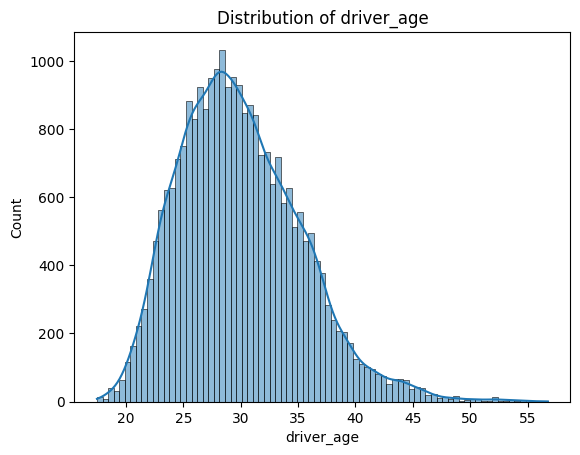

In [9]:
hist(df, "driver_age")

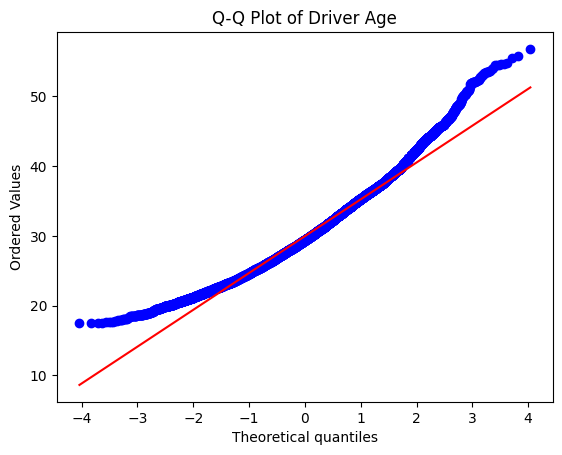

In [10]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(
    df["driver_age"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Driver Age")

plt.show()

In [11]:
from scipy.stats import mannwhitneyu


# Separate groups
podium_group = df[
    df["podium"] == 1
]["driver_age"]

non_podium_group = df[
    df["podium"] == 0
]["driver_age"]

# T-test
t_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    nan_policy="omit"
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'driver_age' is discriminative.")
    descriminative_numerical_features.append("driver_age")
else:
    print("Fail to reject H0")
    print("The variable 'driver_age' is class independent.")

T-statistic: 42559063.5
P-value: 1.656553146433306e-17
Reject H0
The variable 'driver_age' is discriminative.


In [12]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["front_row"],
    df["podium"]
)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Front row starts are associated with podium finishes.")
    descriminative_categorical_features.append("front_row")
else:
    print("Fail to reject H0")
    print("Front row starts are independent of podium finishes.")

Chi-square statistic: 4045.2462825884727
P-value: 0.0
Reject H0
Front row starts are associated with podium finishes.


In [13]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    df["constructor_name"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor name is associated with podium finishes.")
    descriminative_categorical_features.append("constructor_name")
else:
    print("Fail to reject H0")
    print("Constructor name is independent of podium finishes.")

Chi-square statistic: 3711.3602882742834
P-value: 0.0
Reject H0
Constructor name is associated with podium finishes.


In [14]:
# Contingency table
contingency_table = pd.crosstab(
    df["circuit_country"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)


alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Circuit country is associated with podium finishes.")
    descriminative_categorical_features.append("circuit_country")
else:
    print("Fail to reject H0")
    print("Circuit country is independent of podium finishes.")

Chi-square statistic: 9.27955285158374
P-value: 0.999984847062557
Fail to reject H0
Circuit country is independent of podium finishes.


In [15]:
# Contingency table
contingency_table = pd.crosstab(
    df["driver_nationality"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Driver nationality is associated with podium finishes.")
    descriminative_categorical_features.append("driver_nationality")
else:
    print("Fail to reject H0")
    print("Driver nationality is independent of podium finishes.")

Chi-square statistic: 795.4696292875008
P-value: 8.634066317202463e-142
Reject H0
Driver nationality is associated with podium finishes.


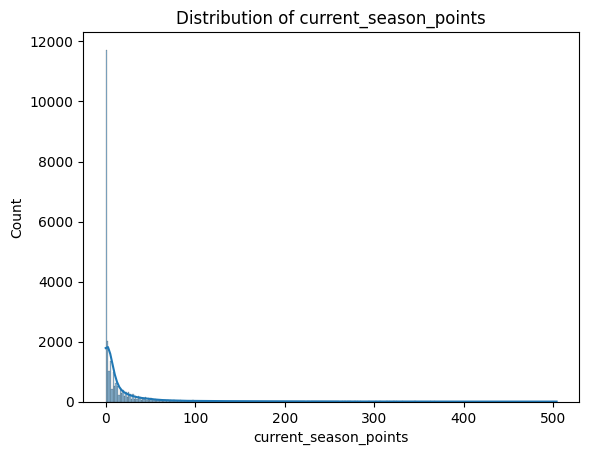

In [16]:
hist(
    df,
    "current_season_points")

In [17]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["current_season_points"]

non_podium_group = df[
    df["podium"] == 0
]["current_season_points"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Current season points is discriminative.")
    descriminative_numerical_features.append("current_season_points")
else:
    print("Fail to reject H0")
    print("Current season points is class independent.")

U-statistic: 58953609.0
P-value: 0.0
Reject H0
Current season points is discriminative.


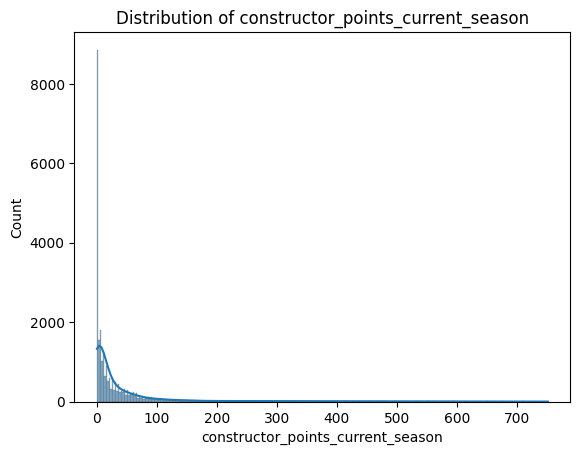

In [18]:
hist(df, "constructor_points_current_season")

In [19]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["constructor_points_current_season"]

non_podium_group = df[
    df["podium"] == 0
]["constructor_points_current_season"]

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor points is discriminative.")
    descriminative_numerical_features.append("constructor_points_current_season")
else:
    print("Fail to reject H0")
    print("Constructor points is class independent.")

U-statistic: 58249338.5
P-value: 0.0
Reject H0
Constructor points is discriminative.


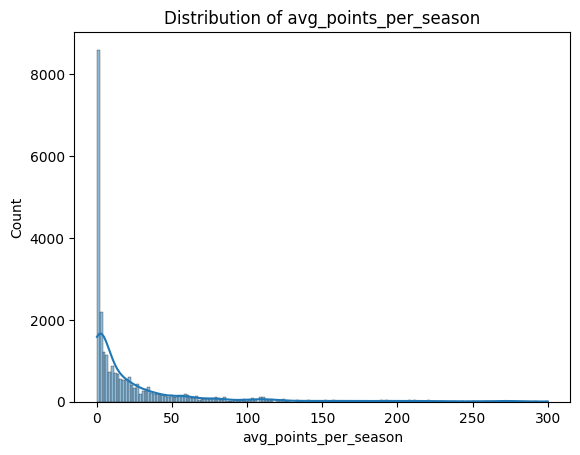

In [20]:
hist(df, "avg_points_per_season")

In [21]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["avg_points_per_season"]

non_podium_group = df[
    df["podium"] == 0
]["avg_points_per_season"]
# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Average points per season is discriminative.")
    descriminative_numerical_features.append("avg_points_per_season")
else:
    print("Fail to reject H0")
    print("Average points per season is class independent.")

U-statistic: 57611119.0
P-value: 0.0
Reject H0
Average points per season is discriminative.


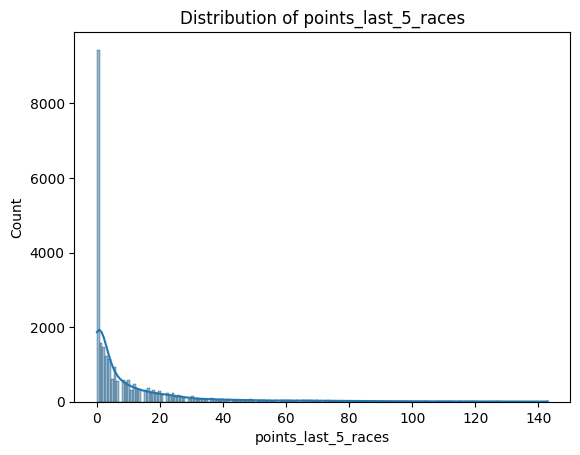

In [22]:
hist(df, "points_last_5_races")

In [23]:
podium_group = df[
    df["podium"] == 1
]["points_last_5_races"]

non_podium_group = df[
    df["podium"] == 0
]["points_last_5_races"]

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("points_last_5_races is discriminative.")
    descriminative_numerical_features.append("points_last_5_races")

else:
    print("Fail to reject H0")
    print("points_last_5_races is class independent.")

U-statistic: 63661232.5
P-value: 0.0
Reject H0
points_last_5_races is discriminative.


In [24]:
correlation_matrix = (
    df[descriminative_numerical_features]
    .corr()
)

correlation_matrix

,q1_seconds,q2_seconds,q3_seconds,weighted_points_at_circuit,driver_circuit_delta,grid,driver_age,current_season_points,constructor_points_current_season,avg_points_per_season,points_last_5_races
q1_seconds,1.000000,0.637880,0.476197,-0.315967,0.022482,0.093359,0.258936,-0.320728,-0.318824,-0.425024,-0.344666
q2_seconds,0.637880,1.000000,0.759214,-0.419032,0.042659,0.276531,0.157539,-0.434354,-0.435257,-0.532499,-0.489152
q3_seconds,0.476197,0.759214,1.000000,-0.468321,0.032815,0.364487,0.099783,-0.513560,-0.508569,-0.554133,-0.583102
weighted_points_at_circuit,-0.315967,-0.419032,-0.468321,1.000000,0.390533,-0.325313,0.108466,0.569270,0.531106,0.791173,0.672259
driver_circuit_delta,0.022482,0.042659,0.032815,0.390533,1.000000,0.041779,0.050315,-0.042683,-0.050124,0.002537,-0.054569
grid,0.093359,0.276531,0.364487,-0.325313,0.041779,1.000000,-0.057301,-0.350153,-0.342130,-0.330706,-0.459572
driver_age,0.258936,0.157539,0.099783,0.108466,0.050315,-0.057301,1.000000,-0.029959,-0.015882,0.099421,-0.013952
current_season_points,-0.320728,-0.434354,-0.513560,0.569270,-0.042683,-0.350153,-0.029959,1.000000,0.954218,0.638751,0.785826
constructor_points_current_season,-0.318824,-0.435257,-0.508569,0.531106,-0.050124,-0.342130,-0.015882,0.954218,1.000000,0.591487,0.736425
avg_points_per_season,-0.425024,-0.532499,-0.554133,0.791173,0.002537,-0.330706,0.099421,0.638751,0.591487,1.000000,0.736505


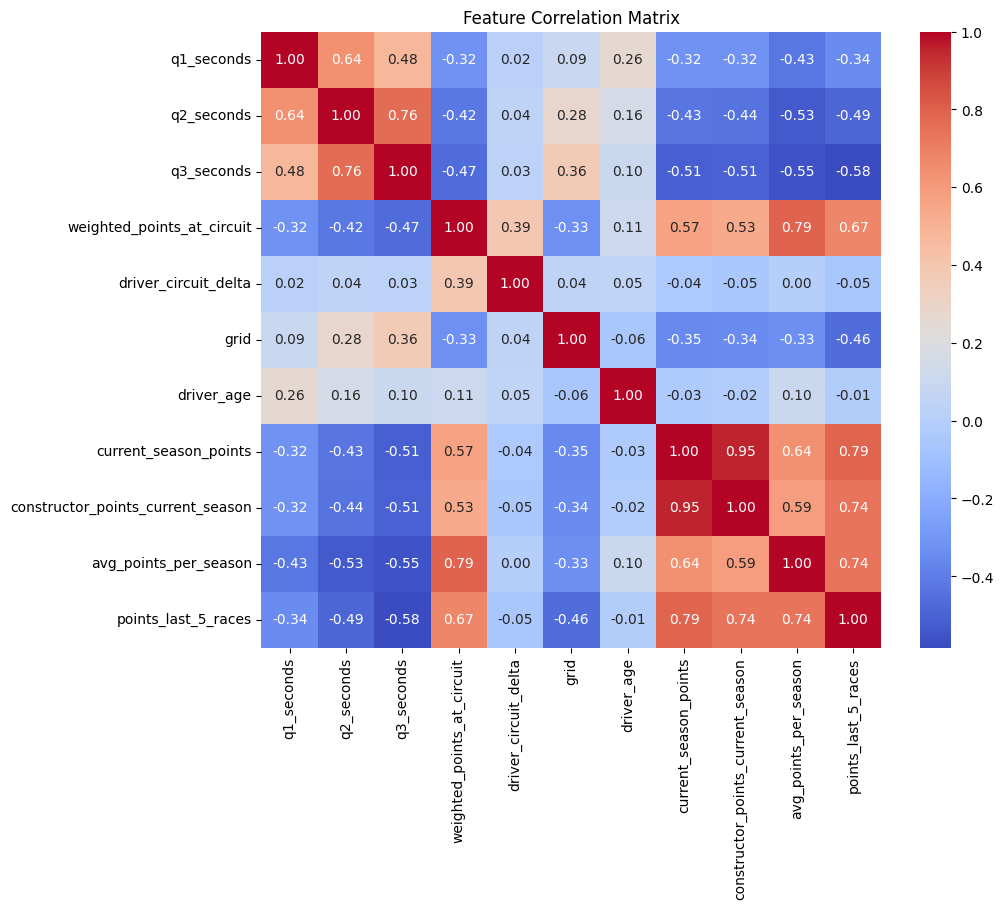

In [25]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [26]:
corr_matrix = (
    df[descriminative_numerical_features]
    .corr()
    .abs()
)

# Upper triangle only
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

# Find features with correlation > 0.9
high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.9)
]

print(high_corr_features)

['constructor_points_current_season']


In [27]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):

    contingency_table = pd.crosstab(x, y)

    chi2 = chi2_contingency(contingency_table)[0]

    n = contingency_table.sum().sum()

    r, k = contingency_table.shape

    return np.sqrt(
        chi2 / (n * (min(r, k) - 1))
    )

In [28]:
cramers_matrix = pd.DataFrame(
    index=descriminative_categorical_features,
    columns=descriminative_categorical_features
)

for col1 in descriminative_categorical_features:
    for col2 in descriminative_categorical_features:

        cramers_matrix.loc[col1, col2] = (
            cramers_v(
                df[col1],
                df[col2]
            )
        )

cramers_matrix

,circuit_id,front_row,constructor_name,driver_nationality
circuit_id,1.0,0.048383,0.181205,0.126681
front_row,0.048383,0.999785,0.323896,0.157325
constructor_name,0.181205,0.323896,1.0,0.369019
driver_nationality,0.126681,0.157325,0.369019,1.0


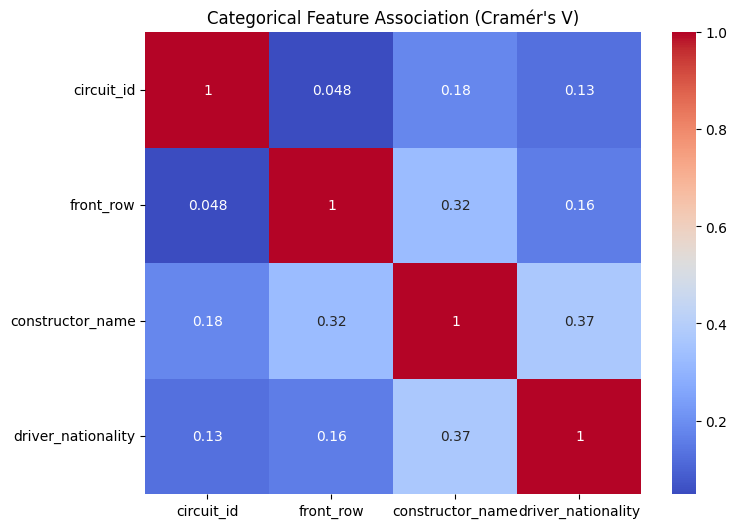

In [29]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cramers_matrix.astype(float),
    annot=True,
    cmap="coolwarm"
)

plt.title("Categorical Feature Association (Cramér's V)")

plt.show()

In [30]:
final_features = (
    descriminative_numerical_features +
    descriminative_categorical_features
)

for f in high_corr_features:
    if f in final_features:
        print(f"Removing {f} due to high correlation.")
        final_features.remove(f)

final_features


print(df["driver_nationality"].isna().sum())

final_features

Removing constructor_points_current_season due to high correlation.
0


['q1_seconds',
 'q2_seconds',
 'q3_seconds',
 'weighted_points_at_circuit',
 'driver_circuit_delta',
 'grid',
 'driver_age',
 'current_season_points',
 'avg_points_per_season',
 'points_last_5_races',
 'circuit_id',
 'front_row',
 'constructor_name',
 'driver_nationality']

In [31]:
X = df[final_features]

y = df["podium"]

In [32]:
from src.data.preprocessing import (
    prepare_chronological_data
)

from src.models.logistic_regression import (
    train_logistic_regression
)

from src.models.evaluate import (
    evaluate_model
)

# Prepare data

X_train, X_test, y_train, y_test, scaler = (
    prepare_chronological_data(
        df,
        final_features,
        scale=True
    )
)

# Train model

model = train_logistic_regression(
    X_train,
    y_train
)

# Predict

# Get probabilities
y_probs = model.predict_proba(X_test)[:, 1]

# Set threshold
threshold = 0.8

# Convert to predictions
y_pred = (y_probs >= threshold).astype(int)

# Evaluate
evaluate_model(y_test, y_pred)

Accuracy: 0.8659833687874686
              precision    recall  f1-score   support

           0       0.97      0.87      0.92      4406
           1       0.53      0.82      0.65       765

    accuracy                           0.87      5171
   macro avg       0.75      0.85      0.78      5171
weighted avg       0.90      0.87      0.88      5171

[[3848  558]
 [ 135  630]]


In [33]:
from src.data.preprocessing import (
    prepare_random_split_data
)

from src.models.random_forest import (
    train_random_forest
)

from src.models.evaluate import (
    evaluate_model
)

# Prepare data

X_train, X_test, y_train, y_test, _ = (
    prepare_random_split_data(
        X,
        y,
        scale=False
    )
)

# Train model

rf_model = train_random_forest(
    X_train,
    y_train
)

# Predict

y_pred_rf = rf_model.predict(
    X_test
)

# Evaluate

evaluate_model(
    y_test,
    y_pred_rf
)

Accuracy: 0.8168851195065536
              precision    recall  f1-score   support

           0       0.97      0.82      0.89      4492
           1       0.41      0.83      0.55       696

    accuracy                           0.82      5188
   macro avg       0.69      0.82      0.72      5188
weighted avg       0.89      0.82      0.84      5188

[[3661  831]
 [ 119  577]]


In [34]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
5,grid,0.265764
9,points_last_5_races,0.139772
8,avg_points_per_season,0.094851
10,front_row,0.094801
7,current_season_points,0.090403
...,...,...
287,constructor_name_Wetteroth,0.000000
301,driver_nationality_Czech,0.000000
304,driver_nationality_East German,0.000000
310,driver_nationality_Indonesian,0.000000


              feature  importance
52  circuit_id_monaco     0.00087


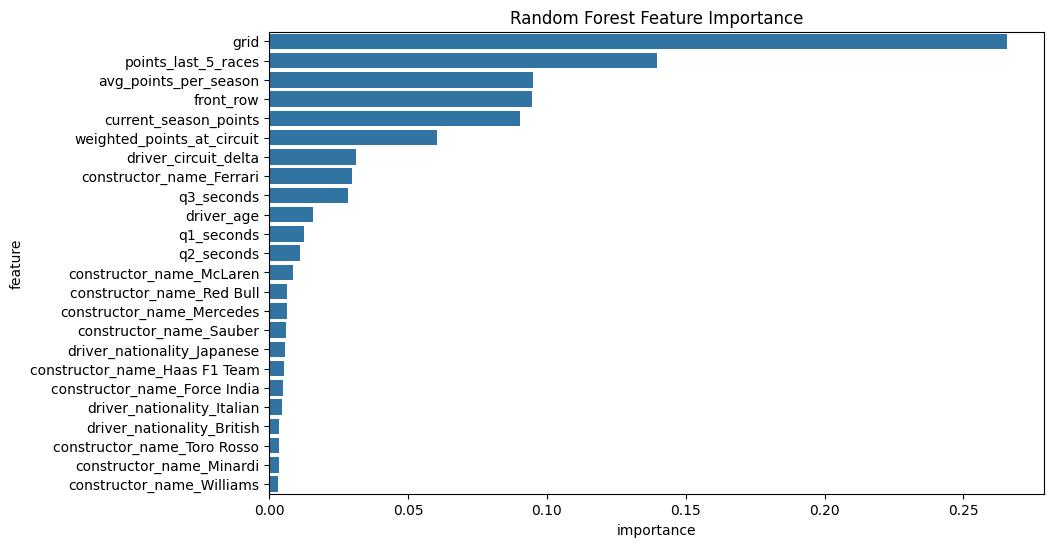

In [35]:
important_features = feature_importance[
    feature_importance["importance"] > 0.002
]

print(
    feature_importance[
        feature_importance["feature"]
        .str.contains("monaco", case=False)
    ]
)


plt.figure(figsize=(10, 6))

sns.barplot(
    data=important_features,
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")

plt.show()

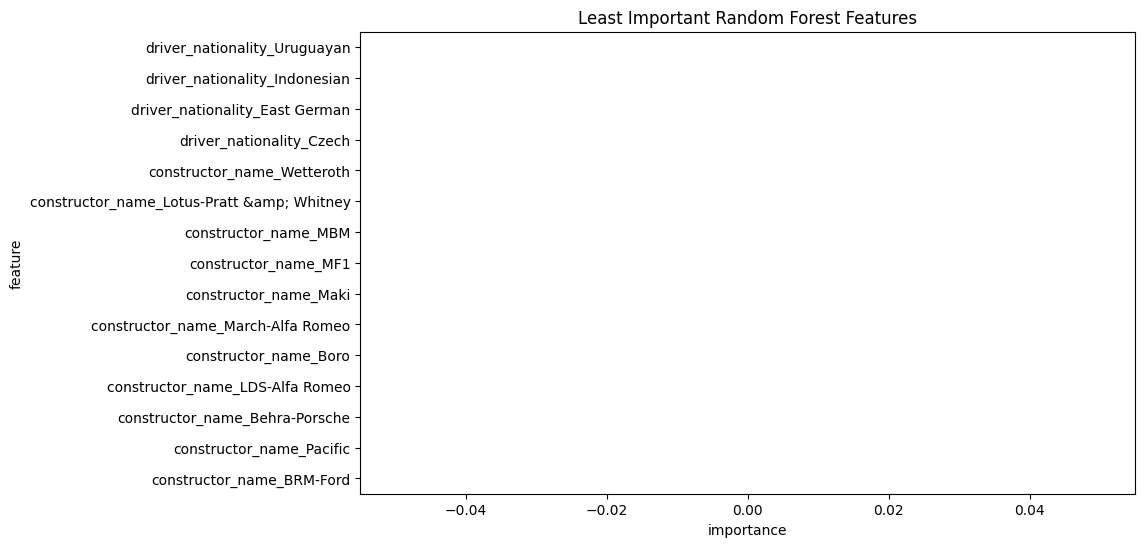

In [36]:
# Least important features

least_important = (
    feature_importance
    .sort_values(by="importance", ascending=True)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=least_important,
    x="importance",
    y="feature"
)

plt.title("Least Important Random Forest Features")

plt.show()

In [37]:
from src.data.preprocessing import (
    prepare_chronological_data
)

X_train, X_test, y_train, y_test, _ = (
    prepare_chronological_data(
        df,
        final_features,
        scale=False
    )
)


In [38]:
from src.models.random_forest import (
    train_random_forest )

rf_model = train_random_forest(
    X_train,
    y_train
)

In [39]:
y_prob = rf_model.predict_proba(X_test)[:, 1]

y_pred_custom = (
    y_prob > 0.70
).astype(int)

In [40]:
from src.models.evaluate import (
    evaluate_model)

evaluate_model(
    y_test,
    y_pred_custom
)

Accuracy: 0.879133629858828
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      4406
           1       0.58      0.67      0.62       765

    accuracy                           0.88      5171
   macro avg       0.76      0.79      0.77      5171
weighted avg       0.89      0.88      0.88      5171

[[4035  371]
 [ 254  511]]


In [41]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
5,grid,0.238223
9,points_last_5_races,0.165274
7,current_season_points,0.106285
8,avg_points_per_season,0.102664
10,front_row,0.098780
...,...,...
74,circuit_id_sochi,0.000000
48,circuit_id_losail,0.000000
51,circuit_id_miami,0.000000
57,circuit_id_mugello,0.000000


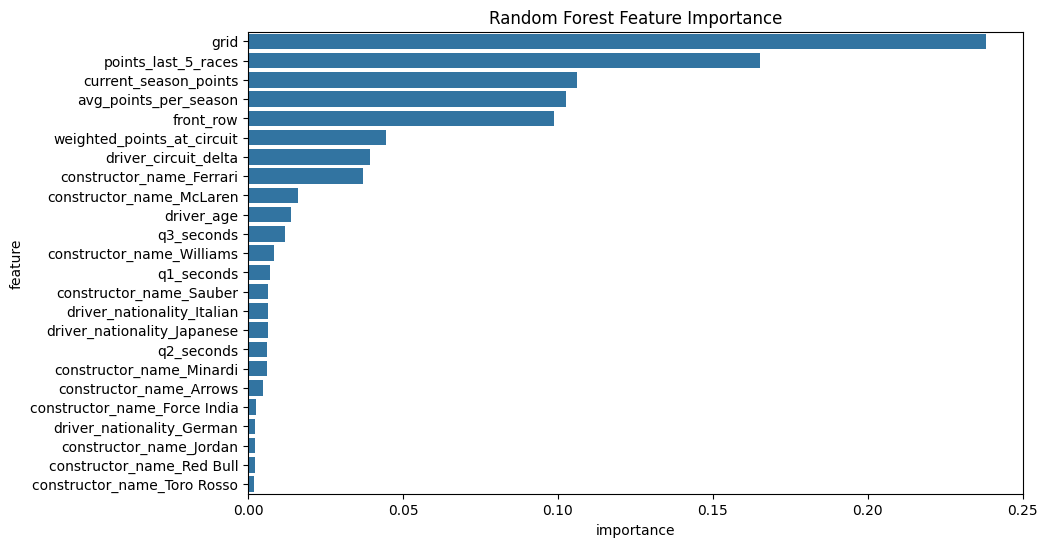

In [42]:
important_features = feature_importance[
    feature_importance["importance"] > 0.002
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=important_features,
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")

plt.show()

In [43]:
from src.models.gradient_boosting import (
    train_gradient_boosting
)

from src.data.preprocessing import (
    prepare_chronological_data
)

X_train, X_test, y_train, y_test, _ = (
    prepare_chronological_data(
        df,
        final_features,
        scale=False,
        split_season=2024
    )
)


gb_model = train_gradient_boosting(
    X_train,
    y_train
)

In [44]:
# Predict probabilities
y_prob = gb_model.predict_proba(X_test)[:, 1]

# Custom threshold
threshold = 0.4

y_pred = (
    y_prob > threshold
).astype(int)

In [45]:
evaluate_model(
    y_test,
    y_pred
)

Accuracy: 0.9174311926605505
              precision    recall  f1-score   support

           0       0.97      0.94      0.95       464
           1       0.69      0.81      0.75        81

    accuracy                           0.92       545
   macro avg       0.83      0.88      0.85       545
weighted avg       0.93      0.92      0.92       545

[[434  30]
 [ 15  66]]


In [46]:
# Get probabilities for podium class
y_probs = gb_model.predict_proba(X_test)[:, 1]

# Create evaluation dataframe
test_df = X_test.copy()

# Add metadata back
test_df["season"] = df.loc[X_test.index, "season"]
test_df["round"] = df.loc[X_test.index, "round"]
test_df["driver_name"] = df.loc[X_test.index, "driver_name"]

# Add actual labels and predicted probabilities
test_df["actual_podium"] = y_test.values
test_df["podium_probability"] = y_probs

# Sort drivers by probability within each race
top3_predictions = (
    test_df
    .sort_values(
        by=["season", "round", "podium_probability"],
        ascending=[True, True, False]
    )
    .groupby(["season", "round"])
    .head(3)
)

# Evaluate performance
correct_predictions = top3_predictions["actual_podium"].sum()

total_predictions = len(top3_predictions)

top3_precision = correct_predictions / total_predictions

print(f"Top-3 Precision: {top3_precision:.3f}")

# Show predicted podiums race-by-race
for (season, rnd), race in top3_predictions.groupby(
    ["season", "round"]
):

    print(f"\nSeason {season} - Round {rnd}")

    print(
        race[
            [
                "driver_name",
                "podium_probability",
                "actual_podium"
            ]
        ]
        .sort_values(
            by="podium_probability",
            ascending=False
        )
    )

Top-3 Precision: 0.728

Season 2025 - Round 1
          driver_name  podium_probability  actual_podium
25394    Lando Norris            0.760258              1
25395  Max Verstappen            0.665739              1
25402   Oscar Piastri            0.606069              0

Season 2025 - Round 2
          driver_name  podium_probability  actual_podium
25416  George Russell            0.794311              1
25414   Oscar Piastri            0.678092              1
25417  Max Verstappen            0.648322              0

Season 2025 - Round 3
          driver_name  podium_probability  actual_podium
25434  Max Verstappen            0.879926              1
25435    Lando Norris            0.783693              1
25436   Oscar Piastri            0.621756              1

Season 2025 - Round 4
           driver_name  podium_probability  actual_podium
25454    Oscar Piastri            0.814872              1
25457  Charles Leclerc            0.658912              0
25459   Max Verstappen     

In [52]:
from src.models.xgboost import (
    train_xgboost
)

from src.data.preprocessing import (
    prepare_chronological_data
)

X_train, X_test, y_train, y_test, _ = (
    prepare_chronological_data(
        df,
        final_features,
        scale=False,
        split_season=2024
    )
)


xgb_model = train_xgboost(
    X_train,
    y_train,
    "xgboost_model_2024"
)

Model saved.


In [74]:
# Predict probabilities
y_prob = xgb_model.predict_proba(X_test)[:, 1]

# Custom threshold
threshold = 0.77

y_pred = (
    y_prob > threshold
).astype(int)

evaluate_model(
    y_test,
    y_pred
)

Accuracy: 0.9229357798165138
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       464
           1       0.71      0.80      0.76        81

    accuracy                           0.92       545
   macro avg       0.84      0.87      0.86       545
weighted avg       0.93      0.92      0.92       545

[[438  26]
 [ 16  65]]


In [55]:
# Get probabilities for podium class
y_probs = xgb_model.predict_proba(X_test)[:, 1]

# Create evaluation dataframe
test_df = X_test.copy()

# Add metadata back
test_df["season"] = df.loc[X_test.index, "season"]
test_df["round"] = df.loc[X_test.index, "round"]
test_df["driver_name"] = df.loc[X_test.index, "driver_name"]

# Add actual labels and predicted probabilities
test_df["actual_podium"] = y_test.values
test_df["podium_probability"] = y_probs

# Sort drivers by probability within each race
top3_predictions = (
    test_df
    .sort_values(
        by=["season", "round", "podium_probability"],
        ascending=[True, True, False]
    )
    .groupby(["season", "round"])
    .head(3)
)

# Evaluate performance
correct_predictions = top3_predictions["actual_podium"].sum()

total_predictions = len(top3_predictions)

top3_precision = correct_predictions / total_predictions

print(f"Top-3 Precision: {top3_precision:.3f}")

# Show predicted podiums race-by-race
for (season, rnd), race in top3_predictions.groupby(
    ["season", "round"]
):

    print(f"\nSeason {season} - Round {rnd}")

    print(
        race[
            [
                "driver_name",
                "podium_probability",
                "actual_podium"
            ]
        ]
        .sort_values(
            by="podium_probability",
            ascending=False
        )
    )

Top-3 Precision: 0.790

Season 2025 - Round 1
          driver_name  podium_probability  actual_podium
25394    Lando Norris            0.924498              1
25402   Oscar Piastri            0.910321              0
25395  Max Verstappen            0.876503              1

Season 2025 - Round 2
          driver_name  podium_probability  actual_podium
25414   Oscar Piastri            0.924979              1
25416  George Russell            0.918981              1
25415    Lando Norris            0.881086              1

Season 2025 - Round 3
          driver_name  podium_probability  actual_podium
25434  Max Verstappen            0.951594              1
25435    Lando Norris            0.926399              1
25436   Oscar Piastri            0.877320              1

Season 2025 - Round 4
           driver_name  podium_probability  actual_podium
25454    Oscar Piastri            0.946116              1
25457  Charles Leclerc            0.907492              0
25455   George Russell     